In [1]:
# -*- coding: uft-8 -*-

# Développez une preuve de concept
***

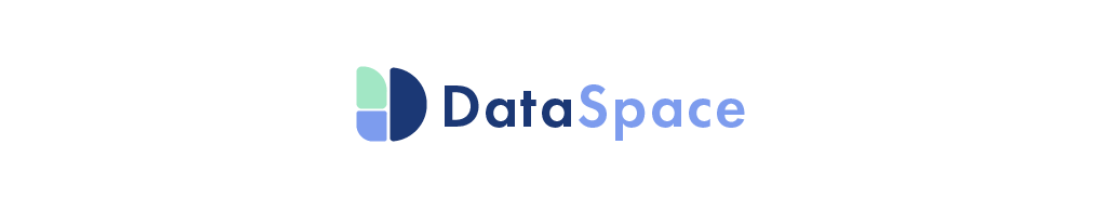

# Mission
## `DataSpace` est une entreprise qui conçoit et mes en place des `des solutions de data science` pour ses clients.<br/> Dans le but de dévolopper une preuve de concept pour cette société nous allons :
### &emsp; 1/ Faire une veille technique / thématique
### &emsp; 2/ <bold>Choisir</bold> un nouveau modèle et le jeu de données qui convient
### &emsp; 3/ <bold>Comparer</bold> notre modèle baseline et le nouveau modèle
### &emsp; 4/ <bold>Valider</bold> notre POC

<a class="anchor" id="sommaire"></a>

### Table des matières

* [1/ Gestion des données](#chapitre1)
    * [1.1/ Import des bibliothèques python et des données](#partie_1_1)
    * [1.2/ Gestion des données](#partie_1_2)
        * [1.2.1/ Récupération des données](#partie_1_2_1)
        * [1.2.2/ Restructurations des données: déplacement et renommage](#partie_1_2_2)
        * [1.2.3/ Mapping des labels: 30 Catégories ==> 8 Catégories](#partie_1_2_3)
    * [1.3/ Générateur de données](#partie_1_3)
* [2/ Modèles de segmentation sémantique](#chapitre2)
    * [2.1/ Modèle Baseline : UNet](#partie_2_1)
    * [2.2/ Nouveau Modèle : HRNet](#partie_2_2)
    * [2.3/ Comparaison](#partie_2_3)

In [3]:
# Install conda/pip packages in the current Jupyter kernel
import sys

'''
# A DECOMMENTER POUR RE-INSTALLER "FROM SCRATCH"

# KERAS (from tensorflow)
# tensorflow==2.10.0 allow more parameters in keras metrics
!{sys.executable} -m pip install tensorflow==2.10.0 
#!{sys.executable} -m pip install tensorflow==2.9.1
!{sys.executable} -m pip install keras-segmentation
#!conda install --yes --prefix {sys.prefix} imageio
#!conda install --yes --prefix {sys.prefix} imgaug


#!conda install --yes --prefix {sys.prefix} seaborn
!{sys.executable} -m pip install tqdm
!{sys.executable} -m pip install h5py
!{sys.executable} -m pip install opencv-python==4.5.5.64
!{sys.executable} -m pip install opencv-contrib-python==4.5.5.64
!{sys.executable} -m pip install pandas
!conda install --yes --prefix {sys.prefix} seaborn


# Visualisation du model
!conda install --yes --prefix {sys.prefix} pydot 
!conda install --yes --prefix {sys.prefix} graphviz


#DASHBOARD
#!conda install --yes --prefix {sys.prefix} flask=2.0.3
!{sys.executable} -m pip install werkzeug==2.0.3
!{sys.executable} -m pip install flask==2.0.3
#!conda install --yes --prefix {sys.prefix} streamlit
#!conda install --yes --prefix {sys.prefix} -c conda-forge streamlit
!{sys.executable} -m pip install streamlit==1.15.2
!{sys.executable} -m pip install --upgrade altair==4.0.0 #compatible strealit < 1.20.0

!{sys.executable} -m pip install dash
!{sys.executable} -m pip install dash_bootstrap_components


# Tensorflow Advanced Segmentation Models
!{sys.executable} -m pip install git+https://github.com/JanMarcelKezmann/TensorFlow-Advanced-Segmentation-Models.git

''';

<a class="anchor" id="chapitre1"></a><hr><center><b><h1><font color=orange>1/ Gestion des données</font></h1></b></center><hr>

<a class="anchor" id="partie_1_1"></a><b><h2><font color=purple>1.1/ Import des bibliothèques python et des données</font></h2></b>

In [3]:
from __future__ import print_function

# Manipulation de données
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Utilaires
import re
import os
from collections import Counter, namedtuple
#import logging
import time
import pickle
from glob import glob
import shutil
from tqdm import tqdm

# My functions
import Guitarian_Guillaume_0_myFunctions_092022 as mfs 

# Model
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import random


# Image 
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import cv2


# Model externe segmentation model
import tensorflow.keras.backend as K
#import segmentation_models as sm
#sm.set_framework('tf.keras')
# segmentation_models could also use `tf.keras` if you do not have Keras installed
# or you could switch to other framework using `sm.set_framework('tf.keras')`


import tensorflow_advanced_segmentation_models as tasm


%matplotlib inline

***
# Configuration Globale

In [4]:
#img_height = 256
#img_width = 512
#batch_size = 16

#img_height = 128
#img_width = 224
#batch_size = 8

#img_height = 128
#img_width = 224
#batch_size = 4

img_height = 128
img_width = 128
batch_size = 4


img_size = (img_height, img_width)
img_size_cv2 = (img_width, img_height)

num_classes = 8


#epochs = 21
epochs = 52

# define network parameters
activation = 'sigmoid' if num_classes == 1 else 'softmax'

CLASSES = ['void', 'flat', 'construction', 'object', 
               'nature', 'sky', 'human', 'vehicle']

# define optomizer
LR = 0.0001
#optim = keras.optimizers.Adam(LR)
optim="adam"

csv_sep = '\t'

def get_model_callbacks(modele_filename ='', history_filename = '', csv_sep = ',', save_weights_only=False):
    
    checkpoint = keras.callbacks.ModelCheckpoint(modele_filename, save_best_only=True, save_weights_only=save_weights_only)
    history_logger=tf.keras.callbacks.CSVLogger(history_filename, separator=csv_sep, append=False)
    early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss',  
                                                  patience=5, 
                                                  verbose=1, 
                                                  mode='auto')
        
    callbacks = [
        checkpoint
        ,early_stop
        ,history_logger
    ]

    return callbacks


# Boolean that gonna drives wich y_true(mask) format is expected by model's metrics and losses
mask_one_hot_encode = False


'''
#All metrics
#metrics = ['sparse_categorical_accuracy', sparseMeanIoU(num_classes=num_classes)]
#metrics = ['sparse_categorical_accuracy', sm.metrics.FScore(threshold=0.5)]
metrics = ['sparse_categorical_accuracy', sm.metrics.IOUScore(threshold=0.5), sm.metrics.FScore(threshold=0.5)]
# Without sparse, for encoded categories of mask file
metrics_EC = ['categorical_accuracy', sm.metrics.IOUScore(threshold=0.5), sm.metrics.FScore(threshold=0.5)] 
''';

# For Sparse y_true (mask file)
mean_IoU_sparse = tf.keras.metrics.MeanIoU(num_classes=num_classes, 
                                           name="mean_IoU",
                                           sparse_y_true=True, 
                                           sparse_y_pred=False)

# For One Hot Encoded y_true (mask file)
mean_IoU_oneHot = tf.keras.metrics.MeanIoU(num_classes=num_classes, 
                                           name="mean_IoU",
                                           sparse_y_true=False, 
                                           sparse_y_pred=False)


# For Sparse y_true (mask file)
metrics_sparse = ['sparse_categorical_accuracy', mean_IoU_sparse]
# For One Hot Encoded y_true (mask file)
metrics_oneHot = ['categorical_accuracy', mean_IoU_oneHot] 



results = {
    'unet2_mobilenet': {
        'training_time_minutes': 0,
        'categorical_accuracy': 0,
        'mean_IoU': 0,
        'loss': 0,
        'nb_epochs': 0
    },'HRNetOCR': {
        'training_time_minutes': 0,
        'categorical_accuracy': 0,
        'mean_IoU': 0,
        'loss': 0,
        'nb_epochs': 0
    }
}


#For one hot encoded masks y_true
if mask_one_hot_encode:
    metrics = metrics_oneHot
    loss = "categorical_crossentropy"
    
    # Function for dice loss
    def dice_loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        smooth = 1e-8
        y_true_f = K.flatten(y_true)
        y_pred_f = K.flatten(y_pred)
        intersection = K.sum(y_true_f * y_pred_f)
        score = (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)
        return 1 - score

    # Function for total loss (dice + categorical_crossentropy)
    def total_loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        ttl_loss = tf.keras.losses.categorical_crossentropy(y_true, y_pred) + (3*dice_loss(y_true, y_pred))
        #ttl_loss = loss(y_true, y_pred) + (3*dice_loss(y_true, y_pred))
        return ttl_loss
    
else:
    #Sparse Mask y_true
    
    metrics = metrics_sparse
    loss = "sparse_categorical_crossentropy"
    
    # Function for dice loss
    def dice_loss(y_true, y_pred):
    
        global num_classes
        y_true_int = tf.dtypes.cast(y_true, tf.uint8)
        y_true_ohe = tf.one_hot(y_true_int, num_classes)
    
        y_true = tf.cast(y_true_ohe, tf.float32)
    
        smooth = 1e-8
        y_true_f = K.flatten(y_true)
        y_pred_f = K.flatten(y_pred)
        intersection = K.sum(y_true_f * y_pred_f)
        score = (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)
        return 1 - score

    # Function for total loss (dice + sparse_categorical_crossentropy)
    def total_loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        ttl_loss = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred) + (3*dice_loss(y_true, y_pred))
        #ttl_loss = loss(y_true, y_pred) + (3*dice_loss(y_true, y_pred))
        return ttl_loss

In [5]:
tf.config.list_physical_devices()

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'),
 PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

<a class="anchor" id="partie_1_2"></a><b><h2><font color=purple>1.2/ Gestion des données</font></h2></b>

### Nous allons utiliser le jeux de données suivant : <a href="https://www.cityscapes-dataset.com/dataset-overview/">Cityscapes</a>

<a class="anchor" id="partie_1_2_1"></a><b><h3><font color=blue>1.2.1/ Récupération des données</font></h3></b>

## Il y a 2 dossiers dans le jeux de données : 

### &emsp;- `leftlmg8bit` contient les images `réelles` (frame de vidéo dans les faits)
### &emsp;- `gtFine` contient (pour chaque image de leftlmg8bit) 4 fichiers d'annotations mais seul 1 des 4 fichiers va nous servir dans notre problématique de `segmentation sémantique` : celui dont le suffixe est `_labelIds.png`. <br> Ce dernier est en fait une image dont la valeur de chaque pixel est l'identifiant du label auquel appartient le pixel de l'image `réelle` correspondante dans le répertoire `leftlmg8bit`<br>Il y a <font color="orange">30 labels distincts en tout</font> qui d'après le <a href="https://github.com/mcordts/cityscapesScripts/blob/master/cityscapesscripts/helpers/labels.py">script de Marius</a>, un des créateurs du jeu de données, se regroupent en 8 catégories de la manière suivante :
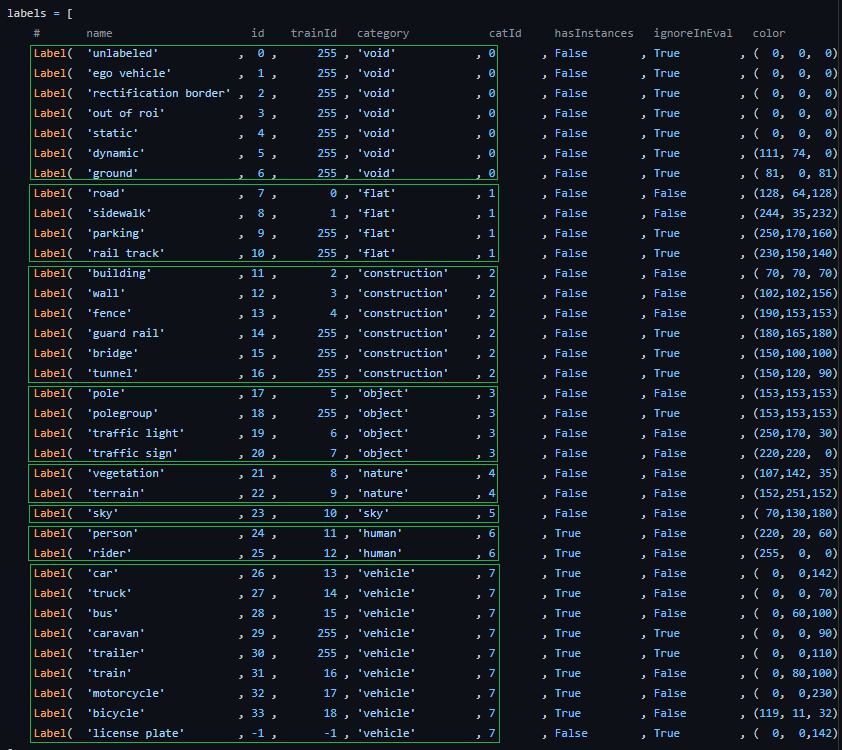

## Dans chacun de ces 2 répertoires, il y a 3 sous-repertoires :
### &emsp;- `test` qui contient 1525 images et annotations qui ne sont pas publiques, sert à l'évaluation sur les serveurs des créateurs du jeux de données, <font color="orange">nous n'utiliserons aucune des images qui y sont contenues !</font> 
### &emsp;- `train` qui contient 2975 images avec des annotations fines et qui sera utilisé pour la partie entrainement en séparant les images à raison de 80% pour le train effectif et 20% pour la partie test.
### &emsp;- `val` qui contient 500 images et annotations et qui sera utilisé comme jeu de `test`

***
<a class="anchor" id="partie_1_2_2"></a><b><h3><font color=blue>1.2.2/ Restructurations des données: déplacement et renommage</font></h3></b>

### Déplacement des images depuis les jeux d'images et masques d'origines vers une arborescence plus pratique

In [6]:
# répertoire courant, ne se termine PAS par un séparateur
current_path = os.path.abspath(os.getcwd())
# Séparateur de chemin d'accès en fonction de l'os
path_sep = os.path.sep

### Les répertoires sources `train` et  `val`<font color="orange">(qui sera la data pour test)</font> ###

In [7]:
# IMAGES #
orig_images_train_path = os.path.join(current_path, 'P8_Cityscapes_leftImg8bit_trainvaltest', 'leftImg8bit', 'train')
orig_images_val_path = os.path.join(current_path, 'P8_Cityscapes_leftImg8bit_trainvaltest', 'leftImg8bit', 'val') 

# MASQUES (ANNOTATIONS) #
orig_rawMasks_train_path = os.path.join(current_path, 'P8_Cityscapes_gtFine_trainvaltest', 'gtFine', 'train')
orig_rawMasks_val_path = os.path.join(current_path, 'P8_Cityscapes_gtFine_trainvaltest', 'gtFine', 'val') 

### Les répertoires de destination `train` et  `val`<font color="orange">(qui sera la data pour test)</font> ###

In [8]:
# IMAGES #
dest_images_train_path = os.path.join(current_path, 'images', 'train')
dest_images_val_path = os.path.join(current_path, 'images', 'val') 

# MASQUES (ANNOTATIONS) #
dest_rawMasks_train_path = os.path.join(current_path, 'annotations', '30', 'train')
dest_rawMasks_val_path = os.path.join(current_path, 'annotations', '30', 'val') 
# Et pour les futurs masques mappés en 8 catégories
dest_masks_train_path = os.path.join(current_path, 'annotations', '8', 'train')
dest_masks_val_path = os.path.join(current_path, 'annotations', '8', 'val') 

### Récupération de la liste des images et masques d'origine à destination des dossiers train et test ### 

In [9]:
# IMAGES #
orig_images_train_files_list = glob(os.path.join(orig_images_train_path, '*', '*.png'))
orig_images_val_files_list = glob(os.path.join(orig_images_val_path, '*', '*.png'))

# MASQUES (ANNOTATIONS) #
orig_rawMasks_train_files_list = glob(os.path.join(orig_rawMasks_train_path, '*', '*_labelIds.png'))
orig_rawMasks_val_files_list = glob(os.path.join(orig_rawMasks_val_path, '*', '*_labelIds.png')) 

In [10]:
print(F"Nombre d'images dans TRAIN : {len(orig_images_train_files_list)}")
print(F"Nombre d'images dans VAL : {len(orig_images_val_files_list)}")

Nombre d'images dans TRAIN : 2975
Nombre d'images dans VAL : 500


### Création des répertoires de destination  

In [11]:
mfs.create_rep_if_not_exist(dest_images_train_path)
mfs.create_rep_if_not_exist(dest_images_val_path)
mfs.create_rep_if_not_exist(dest_rawMasks_train_path)
mfs.create_rep_if_not_exist(dest_rawMasks_val_path)
mfs.create_rep_if_not_exist(dest_masks_train_path)
mfs.create_rep_if_not_exist(dest_masks_val_path)

Le répertoire C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\images\train existe déjà
Le répertoire C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\images\val existe déjà
Le répertoire C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\annotations\30\train existe déjà
Le répertoire C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\annotations\30\val existe déjà
Le répertoire C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\annotations\8\train existe déjà
Le répertoire C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\annotations\8\val existe déjà


### Déplaçons concrètement les images de la source vers la destination

In [12]:
def shutil_copy_files(source_files_paths, dest_path):
    """
    Iterate through all source_files_paths to move corresponding files to dest_path

    Args:
        source_files_paths (list): List of files paths
        dest_path (string): Destination path

    Returns:
        void: Printing results
    """
    already_existing_files_in_directory = True if (len(os.listdir(dest_path)) > 0) else False
    processed_file_counter = 0
    
    if already_existing_files_in_directory:
        print(F"{dest_path} : Répertoire déjà rempli / {processed_file_counter} fichier(s) copié(s).")
    else:
        for file_path in source_files_paths:
            if(os.path.isfile(file_path)):
                processed_file_counter +=1
                shutil.copy(file_path, dest_path)
        print(F"{dest_path} : {processed_file_counter} fichier(s) copié(s).")

In [13]:
%%time
shutil_copy_files(orig_images_train_files_list, dest_images_train_path)
shutil_copy_files(orig_images_val_files_list, dest_images_val_path)
shutil_copy_files(orig_rawMasks_train_files_list, dest_rawMasks_train_path)
shutil_copy_files(orig_rawMasks_val_files_list, dest_rawMasks_val_path)

C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\images\train : Répertoire déjà rempli / 0 fichier(s) copié(s).
C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\images\val : Répertoire déjà rempli / 0 fichier(s) copié(s).
C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\annotations\30\train : Répertoire déjà rempli / 0 fichier(s) copié(s).
C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\annotations\30\val : Répertoire déjà rempli / 0 fichier(s) copié(s).
CPU times: total: 0 ns
Wall time: 0 ns


### Les images et masques correspondants n'ayant pas exectement le même nom de fichier, nous allons remedier à cela pour plus de praticité pour la suite

In [14]:
print(os.listdir(dest_images_train_path)[0])
print(os.listdir(dest_rawMasks_train_path)[0])

aachen_000000_000019.png
aachen_000000_000019.png


In [15]:
def rename_all_dir_files(orig_filenames_paths, dir_path, split_pattern, ext):
    """
    Iterate through all files in dir_path to rename them by removing split_pattern at the end of the file name
    according to original filenames (orig_filenames_paths)

    Args:
        dir_path (string): Path to the directory where files must be renamed
        split_pattern (string): Pattern used in the split process
        ext (string): file extension to keep

    Returns:
        void: Printing results
    """
        
    already_existing_file_counter = 0
    processed_file_counter = 0
    unexisting_file_counter = 0
    
    for file_path in orig_filenames_paths:
        filename = os.path.basename(file_path)
        src_filename_path = os.path.join(dir_path, filename)
        is_src_file_exists = os.path.isfile(src_filename_path)
        
        # For the new file name we keep the first part (so without the ending pattern) and add the file extension
        new_filename = filename.split(split_pattern)[0] + '.' + ext
        dest_filename_path = os.path.join(dir_path, new_filename)
        is_dest_file_exists = os.path.isfile(dest_filename_path)
        
        if(is_src_file_exists):            
            if(is_dest_file_exists):
                already_existing_file_counter +=1
                os.replace(src_filename_path, dest_filename_path) # we have to replace existing file
            else:
                processed_file_counter +=1
                os.rename(src_filename_path, dest_filename_path)
        else:
            unexisting_file_counter +=1
            if(is_dest_file_exists):
                already_existing_file_counter +=1
                
    print(F"""{dir_path} : 
    {already_existing_file_counter} fichier(s) déjà renommé(s) 
    {processed_file_counter} fichier(s) renommé(s) à l'instant
    {unexisting_file_counter} fichier(s) source absent(s)""")

In [16]:
%%time
rename_all_dir_files(orig_images_train_files_list, dest_images_train_path, '_leftImg8bit', 'png')
rename_all_dir_files(orig_images_val_files_list, dest_images_val_path, '_leftImg8bit', 'png')
rename_all_dir_files(orig_rawMasks_train_files_list, dest_rawMasks_train_path, '_gtFine_labelIds', 'png')
rename_all_dir_files(orig_rawMasks_val_files_list, dest_rawMasks_val_path, '_gtFine_labelIds', 'png')

C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\images\train : 
    2975 fichier(s) déjà renommé(s) 
    0 fichier(s) renommé(s) à l'instant
    2975 fichier(s) source absent(s)
C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\images\val : 
    500 fichier(s) déjà renommé(s) 
    0 fichier(s) renommé(s) à l'instant
    500 fichier(s) source absent(s)
C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\annotations\30\train : 
    2975 fichier(s) déjà renommé(s) 
    0 fichier(s) renommé(s) à l'instant
    2975 fichier(s) source absent(s)
C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\annotations\30\val : 
    500 fichier(s) déjà renommé(s) 
    0 fichier(s) renommé(s) à l'instant
    500 fichier(s) source absent(s)
CPU times: total: 359 ms
Wall time: 454 ms


In [17]:
print(os.listdir(dest_images_train_path)[0])
print(os.listdir(dest_rawMasks_train_path)[0])

aachen_000000_000019.png
aachen_000000_000019.png


<a class="anchor" id="partie_1_2_3"></a><b><h3><font color=blue>1.2.3/ Mapping des labels: 30 Catégories ==> 8 Catégories</font></h3></b>

### Tout comme <a ref="https://github.com/mcordts/cityscapesScripts/blob/master/cityscapesscripts/helpers/labels.py">Github de Marius Cordts</a> nous allons remapper les 30 catégories de pixel en 8 Catégories sur toutes nos images d'annotations (masks) des répertoire train et val 

In [18]:
# Adaptation from the official Cityscapes scripts
# https://github.com/mcordts/cityscapesScripts/blob/master/cityscapesscripts/helpers/labels.py

#--------------------------------------------------------------------------------
# Definitions : 
#--------------------------------------------------------------------------------
# Create tuple subclasses with named fields
Label = namedtuple( 'Label' , [

    'name'        , # The identifier of this label, e.g. 'car', 'person', ... .
                    # We use them to uniquely name the 30 classes

    'id'          , # An integer ID that is associated with this label.

    'categoryId'  , # IDs of labels which match to pixel values
                    # corresponding to the 8 main categories.

    'category'    , # The name of the category that this label belongs to
] )

#--------------------------------------------------------------------------------
# A list of all labels
#--------------------------------------------------------------------------------

labels = [
    #name                             id    catId   category
    Label(  'unlabeled'            ,  0 ,      0 , 'void'),
    Label(  'ego vehicle'          ,  1 ,      0 , 'void'),
    Label(  'rectification border' ,  2 ,      0 , 'void'),
    Label(  'out of roi'           ,  3 ,      0 , 'void'),
    Label(  'static'               ,  4 ,      0 , 'void'),
    Label(  'dynamic'              ,  5 ,      0 , 'void'),
    Label(  'ground'               ,  6 ,      0 , 'void'),
    Label(  'road'                 ,  7 ,      1 , 'flat'),
    Label(  'sidewalk'             ,  8 ,      1 , 'flat'),
    Label(  'parking'              ,  9 ,      1 , 'flat'),
    Label(  'rail track'           , 10 ,      1 , 'flat'),
    Label(  'building'             , 11 ,      2 , 'construction'),
    Label(  'wall'                 , 12 ,      2 , 'construction'),
    Label(  'fence'                , 13 ,      2 , 'construction'),
    Label(  'guard rail'           , 14 ,      2 , 'construction'),
    Label(  'bridge'               , 15 ,      2 , 'construction'),
    Label(  'tunnel'               , 16 ,      2 , 'construction'),
    Label(  'pole'                 , 17 ,      3 , 'object'),
    Label(  'polegroup'            , 18 ,      3 , 'object'),
    Label(  'traffic light'        , 19 ,      3 , 'object'),
    Label(  'traffic sign'         , 20 ,      3 , 'object'),
    Label(  'vegetation'           , 21 ,      4 , 'nature'),
    Label(  'terrain'              , 22 ,      4 , 'nature'),
    Label(  'sky'                  , 23 ,      5 , 'sky'),
    Label(  'person'               , 24 ,      6 , 'human'),
    Label(  'rider'                , 25 ,      6 , 'human'),
    Label(  'car'                  , 26 ,      7 , 'vehicle'),
    Label(  'truck'                , 27 ,      7 , 'vehicle'),
    Label(  'bus'                  , 28 ,      7 , 'vehicle'),
    Label(  'caravan'              , 29 ,      7 , 'vehicle'),
    Label(  'trailer'              , 30 ,      7 , 'vehicle'),
    Label(  'train'                , 31 ,      7 , 'vehicle'),
    Label(  'motorcycle'           , 32 ,      7 , 'vehicle'),
    Label(  'bicycle'              , 33 ,      7 , 'vehicle'),
    Label(  'license plate'        , -1 ,      7 , 'vehicle')]

In [19]:
# Création d'un dictionnaire de mapping
mapped_cat_dict = {label.id: label.categoryId for label in labels}
    
#mapped_cat_dict
print(mapped_cat_dict[30])

7


In [20]:
'''
Dans l'état, mapped_cat_dict ne permet de prendre qu'un entier en entrée (et entre crochet)
Nous pouvons alors créer un object qui fonctionnera comme la méthode get d'un dictionnaire 
mais qui pourra prendre une matrice (tableau numpy) en entrée et fournir également
une matrice en sortie, ce qui va nous permettre de convertir les masques qui seront
au préalable convertie en image numérique.

La fonction de numpy appellé "vectorize" qui prend en entrée une fonction, nous permet de le faire.
'''
mapped_cat_vect = np.vectorize(mapped_cat_dict.get)

In [21]:
print(F"""Comme par exemple l'entrée des labels30 [[22 ,11], [33 ,7]] nous donnera les labels8: 
{mapped_cat_vect([[22 ,11], [33 ,7]])}""")

Comme par exemple l'entrée des labels30 [[22 ,11], [33 ,7]] nous donnera les labels8: 
[[4 2]
 [7 1]]


In [22]:
def convert_mask_and_save(mask_30categ_path, mask_8categ_path, mapper, forced=False):
    """
    Iterate through all masks image in mask_30categ_path to convert them into 8 Categories masks image files
    thanks to the mapper and save them to mask_8categ_path directory

    Args:
        mask_30categ_path (string): Path to the 30 Categories masks files
        mask_8categ_path (string): Path to the 8 Categories masks files
        mapper (numpy.vectorize): Object that have been created thanks to the labels mapping dictionnary
        forced (boolean): If flag is true then we create 8 categ mask files again

    Returns:
        void: Printing results
    """
    
    # Counters
    already_existing_file_counter = 0
    processed_file_counter = 0
    
    # Getting all the mask_30categ_path files names
    mask_30categ_filename_list = os.listdir(mask_30categ_path)
    
    for i in range(0, len(mask_30categ_filename_list)): # from 0 index to len(mask_30categ_filename_list)-1
        
        # Getting the filename
        mask_30categ_filename = mask_30categ_filename_list[i]
        
        # Getting the total path to the file (30masks)
        mask_30categ_filename_path = os.path.join(mask_30categ_path, mask_30categ_filename)
        # And the total path to the file (8masks)
        mask_8categ_filename_path = os.path.join(mask_8categ_path, mask_30categ_filename)
        
        # If destination mask file already existing, we will not create it again unless forced flag is true
        is_dest_file_exists = os.path.isfile(mask_8categ_filename_path)
        
        if(is_dest_file_exists):
            already_existing_file_counter += 1
        
        if(not is_dest_file_exists or forced):
            
            processed_file_counter += 1
           
            # Getting the exact file in gray (numpy array)
            mask_30categ_file_arr = cv2.imread(mask_30categ_filename_path, cv2.IMREAD_GRAYSCALE)

            # Convert it via the mapper
            mask_8categ_file_arr = mapper(mask_30categ_file_arr)

            # Saving new 8 Categories mask file to the destination path        
            cv2.imwrite(mask_8categ_filename_path, mask_8categ_file_arr)

            
    print(F"{mask_8categ_path} : {already_existing_file_counter} fichier(s) existant(s) / {processed_file_counter} fichier(s) traité(s).")

In [23]:
%%time
'''
Pour rappel on a :

Pour nos répertoires de fichier masques mappés en 30 catégories:
dest_rawMasks_train_path ==> ..\P8_Final\annotations\30\train\
dest_rawMasks_val_path = ==> ..\P8_Final\annotations\30\val\

et pour nos répertoire de fichier masques mappés en 8 catégories:
dest_masks_train_path ==> ..\P8_Final\annotations\8\train\
dest_masks_val_path = ==> ..\P8_Final\annotations\8\val\
''' 
# Pour Train
convert_mask_and_save(dest_rawMasks_train_path, dest_masks_train_path, mapped_cat_vect)

# Pour Val
convert_mask_and_save(dest_rawMasks_val_path, dest_masks_val_path, mapped_cat_vect)

C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\annotations\8\train : 2975 fichier(s) existant(s) / 0 fichier(s) traité(s).
C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\annotations\8\val : 500 fichier(s) existant(s) / 0 fichier(s) traité(s).
CPU times: total: 109 ms
Wall time: 141 ms


### Visualisation des données

In [24]:
def display_img_target30_target8(img_path, mask_30categ_path, mask_8categ_path, idx_start=0, nb_lines=3):

    """
    Iterate through some input images and corresponding 30 categ / 8 categ annotations and display them.
    
    Args:
        mask_30categ_path (string): Path to the 30 Categories masks files
        mask_8categ_path (string) : Path to the 8 Categories masks files
        idx_start (int)           : Images start index
        nb_lines (int)            : Numbers of ploted lines

    Returns:
        void: Printing results
    """
    
    img_list = os.listdir(img_path)
    target30_list = os.listdir(mask_30categ_path)
    target8_list = os.listdir(mask_8categ_path)

    for i in range(idx_start, idx_start+nb_lines):
        img = cv2.imread(os.path.join(img_path, img_list[i]))
        
        target30 = load_img(os.path.join(mask_30categ_path, target30_list[i]),color_mode="grayscale", interpolation='nearest')
        target30 = img_to_array(target30)
        #target30 = cv2.imread(os.path.join(mask_30categ_path, target30_list[i]), cv2.IMREAD_GRAYSCALE)
        
        
        #target8 = cv2.imread(os.path.join(mask_8categ_path, target8_list[i]), cv2.IMREAD_GRAYSCALE)
        target8 = load_img(os.path.join(mask_8categ_path, target8_list[i]),color_mode="grayscale", interpolation='nearest')
        target8 = img_to_array(target8)
        
        # Plot
        fig, (ax1,ax2,ax3) = plt.subplots(1, 3, figsize=(20, 20))
        ax1.imshow(img)
        ax1.set_title('Image Originelle')
        ax1.axis('off')
        ax2.imshow(target30, cmap='nipy_spectral')
        ax2.set_title('Annotations (30 categ)')
        ax2.axis('off')
        ax3.imshow(target8, cmap='nipy_spectral_r')
        ax3.set_title('Annotations (8 categ)')
        ax3.axis('off')

        plt.show()

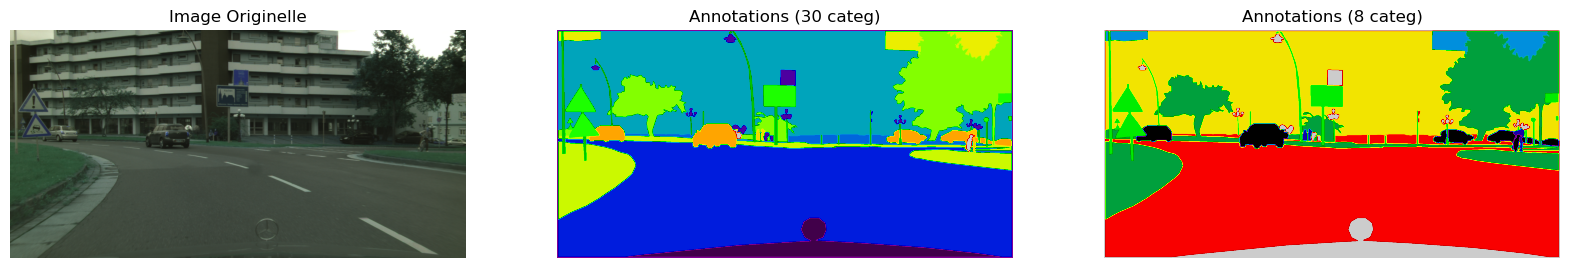

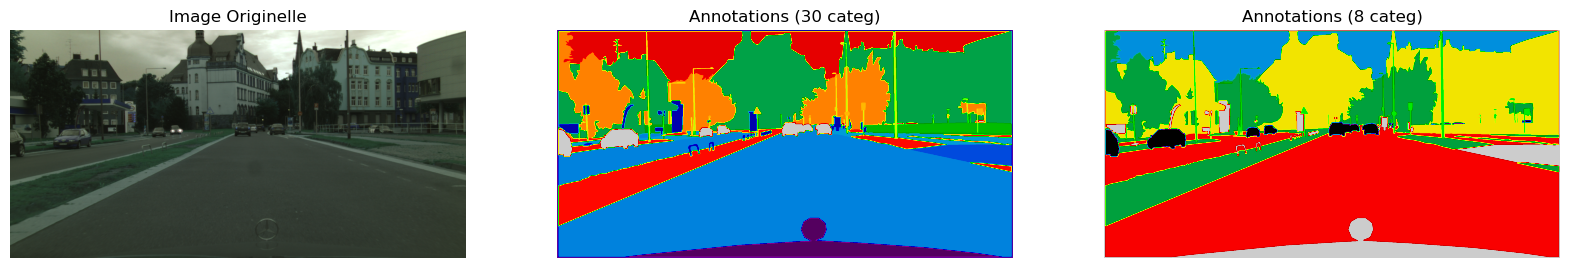

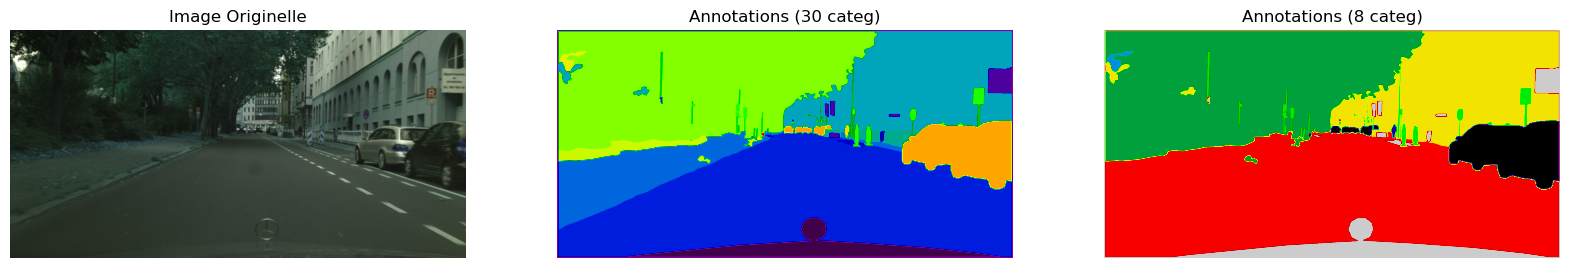

In [25]:
'''
RAPPEL
dest_images_train_path    ==> ..\P8_Final\images\train\
dest_rawMasks_train_path  ==> ..\P8_Final\annotations\30\train\
dest_masks_train_path     ==> ..\P8_Final\annotations\8\train\

'''

display_img_target30_target8(dest_images_train_path, dest_rawMasks_train_path, dest_masks_train_path)

### Répartition des classes de pixels

In [26]:
# Function to compute and plot classes' distribution
def class_distribution(msk_path, title='Classes distribution', resized=True, method='KERAS'):
    msk_list_fn = os.listdir(msk_path)

    # Create an empty list
    sums = []
    
    # 8 Categ label values list
    height_categ_values_list = list(range(0, 8))
    
    #print(locals())

    # Load image data
    for i in tqdm(range(0, len(msk_list_fn))):
        
        mask_fn = os.path.join(msk_path, msk_list_fn[i])
        
        if resized:
            if method == 'CV2':
                mask = cv2.imread(mask_fn, cv2.IMREAD_GRAYSCALE)
                mask = cv2.resize(mask, dsize=img_size, interpolation=cv2.INTER_NEAREST)
            else:
                mask = load_img(mask_fn, target_size=img_size, color_mode="grayscale", interpolation='nearest')
                mask = img_to_array(mask)
        else:
            if method == 'CV2':
                mask = cv2.imread(mask_fn, cv2.IMREAD_GRAYSCALE)
            else:
                mask = load_img(mask_fn, color_mode="grayscale", interpolation='nearest')
                mask = img_to_array(mask)
    
        # Return a list of occurence of each unique label value
        (unique, counts) = np.unique(mask, return_counts=True)

        # Store the result in a list of dictionary
        sums.append(dict(zip(unique, counts)))
        
        
    #return unique, counts, sums

    
    # Instantiate a counter
    result_counter = Counter()

    # Iterate over elements in sums
    for elem_dic in sums:
        for key, value in elem_dic.items():
            result_counter[key] += value
        
    '''
    result_counter[11] = 100000000
    result_counter[10] = 100000000
    result_counter[-1] = 100000000
    ''';
       
    # In case of there was out of scope label value after mask resize (interpolation)
    final_counter = Counter()
    other_categ_pixel_idx = 8
    
    categ = {0:'void', 1:'flat', 2:'construction', 3:'object', 
             4:'nature', 5:'sky', 6:'human', 7:'vehicle', other_categ_pixel_idx:'OTHERS'}
    color_map = {0:'mistyrose', 1:'silver', 2:'teal', 3:'goldenrod',
                 4:'forestgreen', 5:'deepskyblue', 6:'bisque', 7:'orangered', other_categ_pixel_idx:'magenta'}
    
    #Establishing the true right counter
    for k, v in result_counter.items():
        if k not in height_categ_values_list:
            final_counter[8] += v # Class "OTHERS"
        else:
            final_counter[k] = v 
            
    #Removing unexisting label values   
    existing_label_categ = list(final_counter.keys())
    # 8 Categ label values list + OTHERS
    all_categ_values_plus_others_list = list(range(0, 9))
    for label_value in all_categ_values_plus_others_list:
        if label_value not in existing_label_categ:
            del categ[label_value]
            del color_map[label_value]
    
    # Plot the classes distribution
    plt.figure()
    plt.bar(x=categ.values(), height=final_counter.values(),
            tick_label=list(categ.values()), color=color_map.values())
    plt.xticks(rotation=45)
    plt.title(title)
    plt.show()
    
    #return final_counter

100%|██████████| 2975/2975 [00:22<00:00, 132.28it/s]


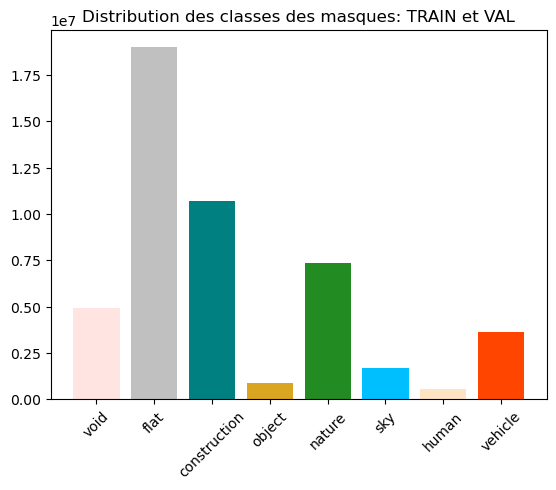

In [27]:
'''
RAPPEL
Nos répertoire de fichier masques mappés en 8 catégories:
dest_masks_train_path ==> ..\P8_Final\annotations\8\train\
dest_masks_val_path = ==> ..\P8_Final\annotations\8\val\

'''
class_distribution(dest_masks_train_path, 'Distribution des classes des masques: TRAIN et VAL')

100%|██████████| 500/500 [00:03<00:00, 132.86it/s]


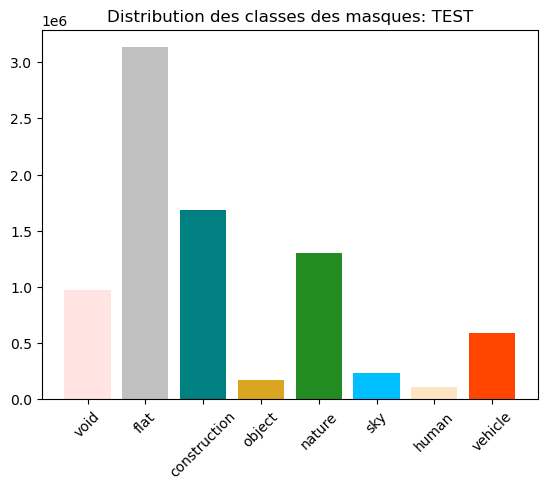

In [28]:
class_distribution(dest_masks_val_path, 'Distribution des classes des masques: TEST')

### Il n'y a donc pas de classes non attendues même après le `resize` des masques de segmentations et l'on remarque même que la distribution entre le jeu de TRAIN et TEST est quasiment identique. Il y a ceci-dit une grande disparité entre les différentes catégories de pixels ce qu'il faudra bien prendre en compte dans les métriques utilisées.

<a class="anchor" id="partie_1_3"></a><b><h2><font color=purple>1.3/ Générateur de données</font></h2></b>

***
### Commençons par séparer les données de Training et validation

In [29]:
input_dir = dest_images_train_path # "images/train/"
target_dir = dest_masks_train_path # "annotations/8/train/"


input_img_paths = sorted(
    [
        os.path.join(input_dir, fname)
        for fname in os.listdir(input_dir)
        if fname.endswith(".png")
    ]
)
target_img_paths = sorted(
    [
        os.path.join(target_dir, fname)
        for fname in os.listdir(target_dir)
        if fname.endswith(".png") 
    ]
)

print("Number of samples:", len(input_img_paths))

for input_path, target_path in zip(input_img_paths[:10], target_img_paths[:10]):
    print(input_path, "|", target_path)
    

# TEST DATASET PATHS
test_input_img_paths = sorted(
    [
        os.path.join(dest_images_val_path, fname)
        for fname in os.listdir(dest_images_val_path)
        if fname.endswith(".png")
    ]
)
test_target_img_paths = sorted(
    [
        os.path.join(dest_masks_val_path, fname)
        for fname in os.listdir(dest_masks_val_path)
        if fname.endswith(".png")
    ]
)

Number of samples: 2975
C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\images\train\aachen_000000_000019.png | C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\annotations\8\train\aachen_000000_000019.png
C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\images\train\aachen_000001_000019.png | C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\annotations\8\train\aachen_000001_000019.png
C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\images\train\aachen_000002_000019.png | C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\annotations\8\train\aachen_000002_000019.png
C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\images\train\aachen_000003_000019.png | C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\annotations\8\train\aachen_000003_000019.png
C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\images\train\aachen_000004_000019.png | C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\annotations\8\train\aachen_000004_000019.png
C:\Users\conra\MesNoteBooks\P10_DEBUG_HRNET\images\train\aachen_000005_000019.png | C:\Users\conra\MesNoteBooks

In [30]:
'''
import random
testlist = ['ça', 'sent', 'la', 'croquette', 'par', 'ici']
random.Random(1337).shuffle(testlist)
testlist
''';

In [31]:
val_samples = 595 # 20% de train
random.Random(1337).shuffle(input_img_paths)
random.Random(1337).shuffle(target_img_paths)
train_input_img_paths = input_img_paths[:-val_samples]
train_target_img_paths = target_img_paths[:-val_samples]
val_input_img_paths = input_img_paths[-val_samples:]
val_target_img_paths = target_img_paths[-val_samples:]

***
### Preparation du Dataloader et des méthodes utilitaires 

In [32]:
# classes for data loading
class Dataset:
    """Dataset. Read images
    Args:
        images_fps (str): list of images files names and path
        masks_fps (str): list of segmentation masks files names and path
        class_values (list): values of classes to extract from segmentation mask 
    """
    
    CLASSES = ['void', 'flat', 'construction', 'object', 
               'nature', 'sky', 'human', 'vehicle']
    
    def __init__(
            self, 
            images_fps, 
            masks_fps, 
            classes=None, 
            maskOneHotEncoded=True
    ):

        self.images_fps = images_fps
        self.masks_fps = masks_fps
        self.maskOneHotEncoded = maskOneHotEncoded
        self.class_nb = len(classes)
        
        if self.maskOneHotEncoded:
            #convert str names to class values on masks
            self.class_values = [self.CLASSES.index(cls.lower()) for cls in classes]
    
    def __getitem__(self, i):
        
        # read data
        image = cv2.imread(self.images_fps[i])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(self.masks_fps[i], 0)
        
        #resizing the image
        image = cv2.resize(image, dsize=img_size_cv2)
        mask = cv2.resize(mask, dsize=img_size_cv2, interpolation=cv2.INTER_NEAREST)
        
        #Pour que le modèle fonctionne 
        image = image.astype(np.float32)
        mask = mask.astype(np.float32)
        
        # extract certain classes from mask (e.g. human, cars)
        if self.maskOneHotEncoded:
            # OLD way
            '''
            masks = [(mask == v) for v in self.class_values]
            mask = np.stack(masks, axis=-1).astype(np.float32)
            ''';
            '''
            print(self.class_values)
            print(mask.shape)
            print(mask)
            print(masks[0].shape)
            print(masks[0])
            print(mask.shape)
            ''';
            # NEW Way
            mask = tf.keras.utils.to_categorical(mask, self.class_nb)   
        
        # add background if mask is not binary
        '''
        if mask.shape[-1] != 1:
            background = 1 - mask.sum(axis=-1, keepdims=True)
            mask = np.concatenate((mask, background), axis=-1)
        '''        
        
        image = image.astype(np.float32)
        image = image/255 # NORMALISATION
        mask = mask.astype(np.float32)
            
        if not self.maskOneHotEncoded:
            mask = np.expand_dims(mask, axis=-1)        
            
            
        #Pour que le modèle fonctionne 
        image = image.astype(np.float32)
        mask = mask.astype(np.float32)
                
        return image, mask
        
        
    def __len__(self):
        return len(self.images_fps)
    
    
class Dataloader(keras.utils.Sequence):
    """Load data from dataset and form batches
    
    Args:
        dataset: instance of Dataset class for image loading.
        batch_size: Integet number of images in batch.
        shuffle: Boolean, if `True` shuffle image indexes each epoch.
    """
    
    def __init__(self, dataset, batch_size=1, shuffle=False):
        self.dataset = dataset
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(dataset))

        self.on_epoch_end()

    def __getitem__(self, i):
        
        # collect batch data
        start = i * self.batch_size
        stop = (i + 1) * self.batch_size
        data = []
        for j in range(start, stop):
            data.append(self.dataset[j])
        
        # transpose list of lists
        batch = [np.stack(samples, axis=0) for samples in zip(*data)]
        
        return batch
    
    def __len__(self):
        """Denotes the number of batches per epoch"""
        return len(self.indexes) // self.batch_size
    
    def on_epoch_end(self):
        """Callback function to shuffle indexes each epoch"""
        if self.shuffle:
            self.indexes = np.random.permutation(self.indexes) 

In [33]:
# helper function for data visualization
def visualize(**images):
    """PLot images in one row."""
    
    n = len(images)
    plt.figure(figsize=(16, 5))
    for i, (name, image) in enumerate(images.items()):
        
        print(image.shape)
        if i==0: #Real image
            img=(image*255).astype(np.uint8)   
        else: # Mask(s)
            img = image/np.max(image)
            img = (img * 255).astype(np.uint8)
        
        plt.subplot(1, n, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.title(' '.join(name.split('_')).title())
        if i==0: #Real image
            plt.imshow(img)
        else:# Mask(s)
            plt.imshow(img, cmap='nipy_spectral_r')
    plt.show()
    
# helper function for data visualization    
def denormalize(x):
    """Scale image to range 0..1 for correct plot"""
    x_max = np.percentile(x, 98)
    x_min = np.percentile(x, 2)    
    x = (x - x_min) / (x_max - x_min)
    x = x.clip(0, 1)
    return x


def display_datagen_info(data_gen):
    """
    Iterate through a batch of image to display some data
    
    Args:
        data_gen (ImageDataGen)   : data generator of resized images and masks (x, y) batches

    Returns:
        void: Printing results
    """
        
    #Batch (tuple) images and masks (x, y)
    data_gen_size = len(data_gen)
    batch_size = len(data_gen[0][0]) #On se base sur X, l'image réel pour avoir la taille d'un batch
    
    if(data_gen_size==1):        
        print(F"Datagenerator composé d'1 seul batch de {batch_size} images et masques")
    else:
        last_batch_index = data_gen_size - 1
        last_batch_size = len(data_gen[last_batch_index][0])
        
        if(batch_size == last_batch_size):
            print(F"Datagenerator composé de {data_gen_size} batches de {batch_size} images et masques")
        else:
            print(F"Datagenerator composé de {data_gen_size - 1} batches de {batch_size} images et masques",
                  "et d'1 dernier batch de {last_batch_size} images et masques")
    
    batch = data_gen[0]

    #IMAGES
    batch_X_img = batch[0]
    # Première image du batch
    batch_X_img_0 = batch_X_img[0]

    print(F"Taille du batch d'image input : {batch_X_img.shape}")
    print(F"Taille d'une image input : {batch_X_img_0.shape}")

    #ANNOTATIONS
    batch_Y_mask = batch[1]
    # Première masque du premier batch
    batch_Y_mask_0 = batch_Y_mask[0]

    print(F"Taille du batch d'annotations: {batch_Y_mask.shape}")
    print(F"Taille d'une image d'annotation : {batch_Y_mask_0.shape}")

In [34]:
def plot_performance(data):
    # modle performance visualization
    # subplot
    fig,(ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 8))
    
    # accuracy
    ax1.plot(data['accuracy'], color='red')
    ax1.plot(data['val_accuracy'], color='green')
    ax1.set_title('Accuracy')
    ax1.set_ylabel('Accuracy')
    ax1.set_xlabel('Epoch')
    ax1.legend(['train', 'validation'], loc='lower right')
    
    # mean IoU
    ax2.plot(data['iou'], color='red')
    ax2.plot(data['val_iou'], color='green')
    ax2.set_title('IOU Score')
    ax2.set_ylabel('IOU Score')
    ax2.set_xlabel('Epoch')
    ax2.legend(['train', 'validation'], loc='lower right')

    # "Loss"
    ax3.plot(data['loss'], color='red')
    ax3.plot(data['val_loss'], color='green')
    ax3.set_title('Model loss')
    ax3.set_ylabel('Loss')
    ax3.set_xlabel('Epoch')
    ax3.legend(['train', 'validation'], loc='upper right')
    plt.show()

In [35]:
def display_batch_predict(model, data_gen, batch_idx=0, idx_start=0, nb_lines=1):
    """
    Iterate through a batch of image to display some source and prediction data
    
    Args:
        model (keras model)       : Trained model
        data_gen (ImageDataGen)   : data generator of resized images and masks (x, y) batches
        batch_idx (int)           : batch index
        idx_start (int)           : Images start index
        nb_lines (int)            : Numbers of ploted lines

    Returns:
        void: Printing results
    """
    max_batch_index = len(data_gen)
    if batch_idx > max_batch_index:
        print(F"Batch index can not exceed {max_batch_index}, please try a lower batch index")
    else:        
        
        #Batch (tuple) images and masks (x, y)
        batch = data_gen[batch_idx]
        print(F"Data for batch #{batch_idx + 1} on {max_batch_index} batches")
        
        #IMAGES
        batch_X_img = batch[0]
        # Première image du batch
        batch_X_img_0 = batch_X_img[0]

        print(F"Taille du batch d'image input : {batch_X_img.shape}")
        print(F"Taille d'une image input : {batch_X_img_0.shape}")

        #ANNOTATIONS
        batch_Y_mask = batch[1]
        # Premier masque du batch
        batch_Y_mask_0 = batch_Y_mask[0]

        print(F"Taille du batch d'annotations: {batch_Y_mask.shape}")
        print(F"Taille d'une image d'annotation : {batch_Y_mask_0.shape}")

        #display(pilImage.fromarray(batch_X_img_0.astype(np.uint8)))
        #img = batch_X_img_0/np.max(batch_X_img_0)
        #img = (img * 255).astype(np.uint8)
        #print(img)
        #display(pilImage.fromarray(img))
        
        global mask_one_hot_encode

        test_preds = model.predict(batch_X_img)
        
        for i in range(idx_start, idx_start+nb_lines):
            
            if i >= len(batch_X_img):
                break
            
            img = (batch_X_img[i]*255).astype(np.uint8)
                
            
            target = batch_Y_mask[i]
            if mask_one_hot_encode:
                target = np.argmax(target, axis=-1)
            
            predicted_mask = np.argmax(test_preds[i], axis=-1)
            predicted_mask = np.expand_dims(predicted_mask, axis=-1)

            # Plot
            fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 20))
            ax1.imshow(img)
            ax1.set_title('Resized input image')
            ax1.axis('off')
            ax2.imshow(target, cmap='nipy_spectral')
            ax2.set_title('Resized annotations(8 Categ) image')
            ax2.axis('off')
            ax3.imshow(predicted_mask, cmap='nipy_spectral')
            ax3.set_title('Predicted annotations(8 Categ) image')
            ax3.axis('off')

            plt.show()

<a class="anchor" id="chapitre2"></a><hr><center><b><h1><font color=orange>2/ Modèles de segmentation sémantique</font></h1></b></center><hr>[](#sommaire)


### Preparation des instances de dataloader

In [36]:
# Dataset for train images
train_dataset = Dataset(
    train_input_img_paths, 
    train_target_img_paths, 
    classes=CLASSES, 
    maskOneHotEncoded=mask_one_hot_encode
)

# Dataset for validation images
valid_dataset = Dataset(
    val_input_img_paths, 
    val_target_img_paths, 
    classes=CLASSES, 
    maskOneHotEncoded=mask_one_hot_encode
)

train_dataloader = Dataloader(train_dataset, batch_size=batch_size, shuffle=True)
valid_dataloader = Dataloader(valid_dataset, batch_size=1, shuffle=False)

# check shapes for errors
assert train_dataloader[0][0].shape == (batch_size, img_height, img_width, 3)
if mask_one_hot_encode:
    assert train_dataloader[0][1].shape == (batch_size, img_height, img_width, num_classes)
else:
    assert train_dataloader[0][1].shape == (batch_size, img_height, img_width, 1)
    
# Dataset for train images
test_dataset = Dataset(
    test_input_img_paths, 
    test_target_img_paths, 
    classes=CLASSES, 
    maskOneHotEncoded=mask_one_hot_encode
)
#test_dataloader = Dataloader(test_dataset, batch_size=batch_size, shuffle=False)
test_dataloader = Dataloader(test_dataset, batch_size=3, shuffle=False)

(128, 128, 3)
(128, 128, 1)


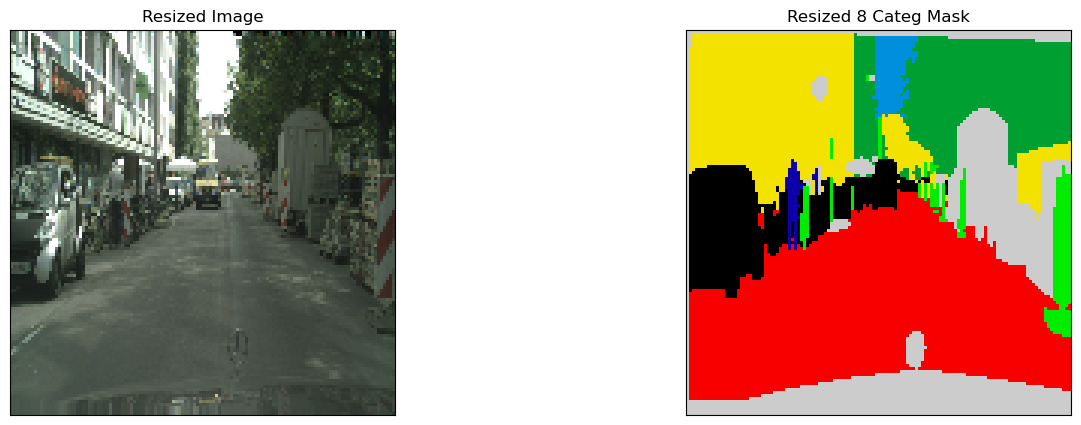

float32 float32


In [37]:
# Lets look at data we have
image, mask = train_dataset[32] # get some sample
if mask_one_hot_encode:
    visualize(
        image=image, 
        human_mask=mask[..., 6].squeeze(), # 7ème position dans CLASSES envoyé en paramètre dans Dataset(...)
        vehicle_mask=mask[..., 7].squeeze(), # 8ème position dans CLASSES envoyé en paramètre dans Dataset(...)
        #background_mask=mask[..., 2].squeeze(),
    )
    
else:
    visualize(
    resized_image=image, 
    resized_8_categ_mask=mask
    )

print(image.dtype, mask.dtype)

<a class="anchor" id="partie_2_1"></a><b><h2><font color=purple>2.1/ Modèle Baseline : UNet</font></h2></b>


### Utilisons le modèle baseline `UNet` avec un backbone `mobilenet` comme pour le P8

In [38]:
BACKBONE = 'mobilenet'
NEW_MODEL = 'Unet2'

In [39]:
%%time
if mask_one_hot_encode:
    modele_name = F'{NEW_MODEL}_{BACKBONE}_ohe'
else:
    modele_name = F'{NEW_MODEL}_{BACKBONE}_sparse'
    
modele_filename = F"model_{modele_name}.h5"
history_filename = F"history_{modele_name}.csv"
var_backup_filename = F"var_backup_{modele_name}.pckl"

is_model_existing = False
try:
    
    # Free up RAM in case the model definition cells were run multiple times
    keras.backend.clear_session()
    
    # Build model
    base_model, layers, layer_names = tasm.create_base_model(name=BACKBONE,  height=img_height, width=img_width)
    model_UNet = tasm.UNet(n_classes=num_classes, base_model=base_model, output_layers=layers, backbone_trainable=True, final_activation=activation).model()
    model_UNet.compile(optimizer=optim, loss=loss, metrics=metrics)
    
    model_UNet.built = True
    model_UNet.load_weights(modele_filename) #Cette version ne fonctionne qu'avec les poids
    
    is_model_existing = True
    
except Exception as e:
    #print(is_model_existing)
    #print(e)
    #print(is_model_existing)
    print(F"Model {modele_name} does not exist, we have to create and fit it")    
    
if not is_model_existing:
    # Free up RAM in case the model definition cells were run multiple times
    keras.backend.clear_session()
    
     # Build model
    base_model, layers, layer_names = tasm.create_base_model(name=BACKBONE,  height=img_height, width=img_width)
    model_UNet = tasm.UNet(n_classes=num_classes, base_model=base_model, output_layers=layers, backbone_trainable=True, final_activation=activation).model()
    model_UNet.compile(optimizer=optim, loss=loss, metrics=metrics)
    #model_UNet.compile(tf.keras.optimizers.Adam(0.0001), loss=tasm.losses.CategoricalFocalLoss, tasm.metrics.IOUScore(threshold=0.5))
    
    
    callbacks = get_model_callbacks(modele_filename, history_filename, csv_sep, save_weights_only=True)
    
    
    start = time.time()
    # Train the model, doing validation at the end of each epoch.
    history = model_UNet.fit(
        train_dataloader, 
        steps_per_epoch=len(train_dataloader), 
        epochs=epochs, 
        #epochs=2,
        callbacks=callbacks, 
        validation_data=valid_dataloader, 
        validation_steps=len(valid_dataloader),
    )
    end = time.time()
    
    
    training_time = round((end - start)/60)
    es = callbacks[1] # early_stopping est dans le 0 ici
    nb_epochs = es.stopped_epoch+1 if (es.stopped_epoch>0 and es.stopped_epoch<epochs) else epochs
    # saving training time and nb of epochs
    var_backup = {
        'training_time': training_time,
        'nb_epochs': nb_epochs
    }
    f = open(var_backup_filename, 'wb')
    pickle.dump(var_backup, f)
    f.close()
    
    hist = history.history.copy()

else:
    print(F"Les poids du modèle {modele_name} existent déjà nous allons les charger dans une instance de modèle")
        
    #Le dataframe principale qui nous serviras pour TFIDF(qu'il faudra calculer)
    history_df = pd.read_csv(history_filename
                                         , sep=csv_sep
                                         , encoding='utf-8'
                                         , low_memory=True
                                         , index_col=False
                                        )
    history_df.set_index('epoch', inplace=True)
    hist = history_df.to_dict('list').copy()
    
    #retrieving saved variables value
    f = open(var_backup_filename, 'rb')
    var_backup = pickle.load(f)
    training_time = var_backup['training_time']
    nb_epochs = var_backup['nb_epochs']
    f.close()


Les poids du modèle Unet2_mobilenet_sparse existent déjà nous allons les charger dans une instance de modèle
CPU times: total: 609 ms
Wall time: 1.49 s


### Visualisation des performances du modèle

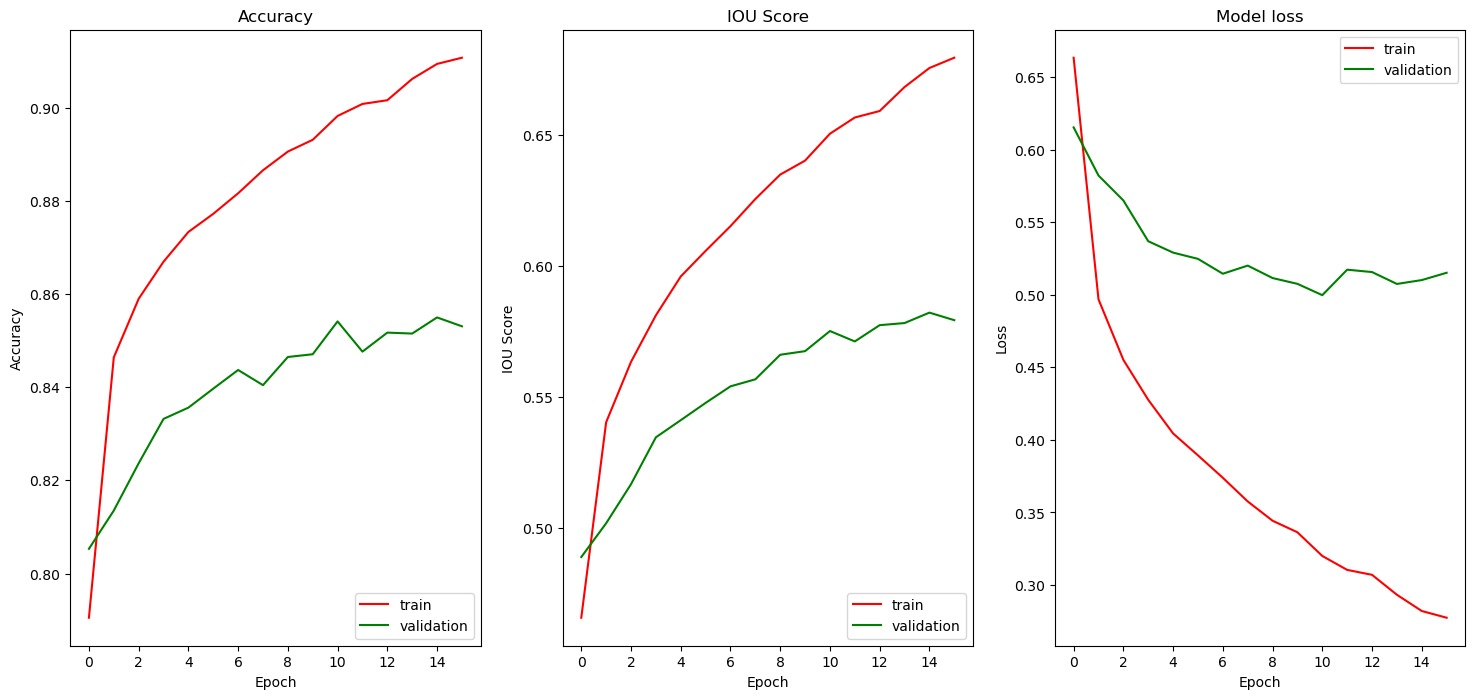

In [40]:
if mask_one_hot_encode:
    hist['accuracy'] = hist.pop('categorical_accuracy')
    hist['val_accuracy'] = hist.pop('val_categorical_accuracy')
else:
    hist['accuracy'] = hist.pop('sparse_categorical_accuracy')
    hist['val_accuracy'] = hist.pop('val_sparse_categorical_accuracy')
    
hist['iou'] = hist.pop('mean_IoU')
hist['val_iou'] = hist.pop('val_mean_IoU')

'''    
for k, v in hist.items():
    print(k, type(v))
''';

plot_performance(hist)

### Visualisation des prédictions et comparaison avec les images réelles et masques 8 categ

Data for batch #6 on 166 batches
Taille du batch d'image input : (3, 128, 128, 3)
Taille d'une image input : (128, 128, 3)
Taille du batch d'annotations: (3, 128, 128, 1)
Taille d'une image d'annotation : (128, 128, 1)
1/1 [==============================] - 4s 4s/step


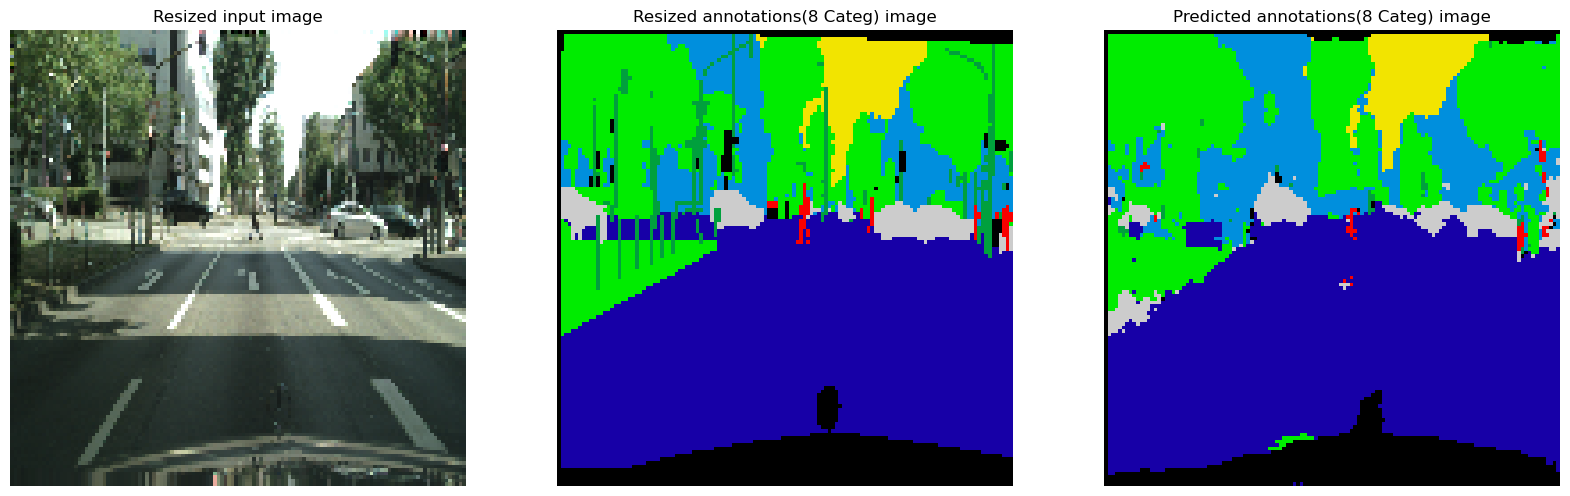

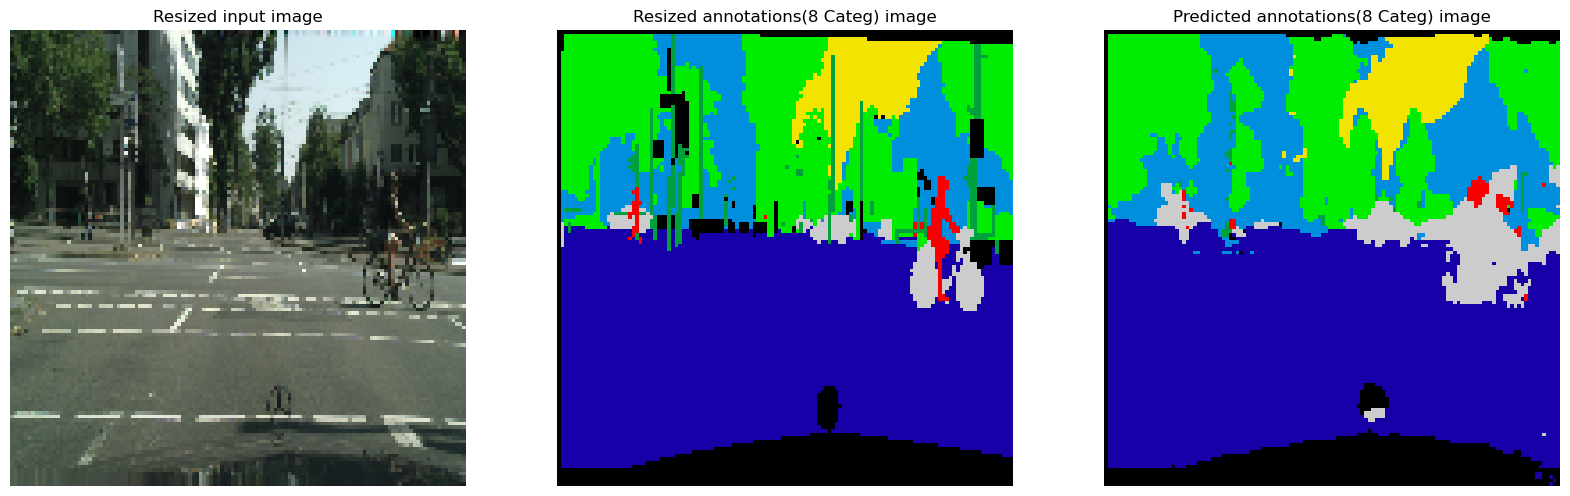

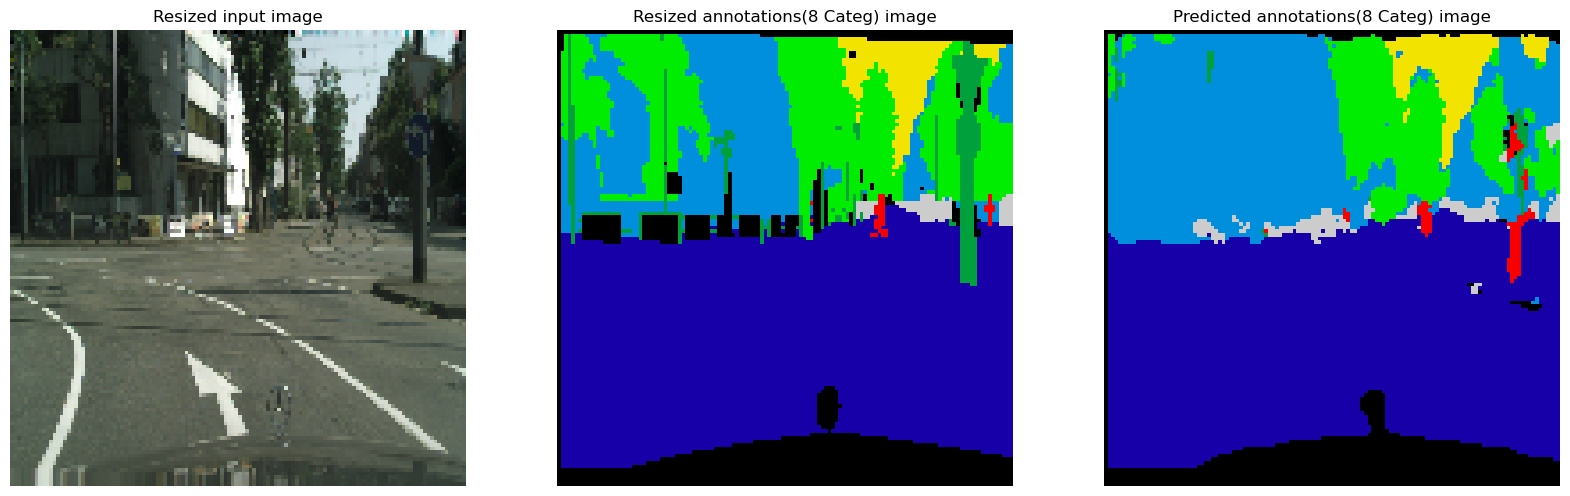

In [41]:
display_batch_predict(model_UNet, test_dataloader, 5,0,3)

### Sauvegarde des résultats d'évaluation,  training_time et nombre d'epochs

In [42]:
results['unet2_mobilenet']['training_time_minutes'] = training_time
results['unet2_mobilenet']['nb_epochs'] = nb_epochs

scores = model_UNet.evaluate(test_dataloader)
print(scores)

results['unet2_mobilenet']['loss'] = scores[0]
results['unet2_mobilenet']['categorical_accuracy'] = scores[1]
results['unet2_mobilenet']['mean_IoU'] = scores[2]

166/166 [==============================] - 21s 115ms/step - loss: 0.5377 - sparse_categorical_accuracy: 0.8500 - mean_IoU: 0.5757
[0.5377019643783569, 0.8499781489372253, 0.5757306814193726]


In [43]:
#results_df = pd.DataFrame.from_dict(results, orient='index')
#results_df

<a class="anchor" id="partie_2_2"></a><b><h2><font color=purple>2.2/ Nouveau Modèle : HRNet</font></h2></b>


### Utilisons à présent le nouveau modèle `HRNet`

In [44]:
BACKBONE = 'none'
NEW_MODEL = 'HRNetOCR'

In [45]:
%%time
if mask_one_hot_encode:
    modele_name = F'{NEW_MODEL}_{BACKBONE}_ohe'
else:
    modele_name = F'{NEW_MODEL}_{BACKBONE}_sparse'
    
modele_filename = F"model_{modele_name}.h5"
history_filename = F"history_{modele_name}.csv"
var_backup_filename = F"var_backup_{modele_name}.pckl"

is_model_existing = False
try:
    
    # Free up RAM in case the model definition cells were run multiple times
    keras.backend.clear_session()
    
    # Build model
    HRNetOCR = tasm.HRNetOCR(n_classes=num_classes, height=img_height, width=img_width, final_activation=activation).model()
    HRNetOCR.compile(optimizer=optim, loss=loss, metrics=metrics)
    
    HRNetOCR.built = True
    HRNetOCR.load_weights(modele_filename) #Cette version ne fonctionne qu'avec les poids
    
    is_model_existing = True
    
except Exception as e:
    #print(is_model_existing)
    #print(e)
    #print(is_model_existing)
    print(F"Model {modele_name} does not exist, we have to create and fit it")    
    
if not is_model_existing:
    # Free up RAM in case the model definition cells were run multiple times
    keras.backend.clear_session()
    
    # Build model
    HRNetOCR = tasm.HRNetOCR(n_classes=num_classes, height=img_height, width=img_width, final_activation=activation).model()
    HRNetOCR.compile(optimizer=optim, loss=loss, metrics=metrics)
    #HRNetOCR.compile(tf.keras.optimizers.Adam(0.0001), loss=tasm.losses.CategoricalFocalLoss, tasm.metrics.IOUScore(threshold=0.5))
    
    
    callbacks = get_model_callbacks(modele_filename, history_filename, csv_sep, save_weights_only=True)
    
    
    start = time.time()
    # Train the model, doing validation at the end of each epoch.
    history = HRNetOCR.fit(
        train_dataloader, 
        steps_per_epoch=len(train_dataloader), 
        epochs=epochs, 
        #epochs=2, 
        callbacks=callbacks, 
        validation_data=valid_dataloader, 
        validation_steps=len(valid_dataloader),
    )
    end = time.time()
    
    
    training_time = round((end - start)/60)
    es = callbacks[1] # early_stopping est dans le 0 ici
    nb_epochs = es.stopped_epoch+1 if (es.stopped_epoch>0 and es.stopped_epoch<epochs) else epochs
    # saving training time and nb of epochs
    var_backup = {
        'training_time': training_time,
        'nb_epochs': nb_epochs
    }
    f = open(var_backup_filename, 'wb')
    pickle.dump(var_backup, f)
    f.close()
    
    hist = history.history.copy()

else:
    print(F"Les poids du modèle {modele_name} existent déjà nous allons les charger dans une instance de modèle")
        
    #Le dataframe principale qui nous serviras pour TFIDF(qu'il faudra calculer)
    history_df = pd.read_csv(history_filename
                                         , sep=csv_sep
                                         , encoding='utf-8'
                                         , low_memory=True
                                         , index_col=False
                                        )
    history_df.set_index('epoch', inplace=True)
    hist = history_df.to_dict('list').copy()
    
    #retrieving saved variables value
    f = open(var_backup_filename, 'rb')
    var_backup = pickle.load(f)
    training_time = var_backup['training_time']
    nb_epochs = var_backup['nb_epochs']
    f.close()


Les poids du modèle HRNetOCR_none_sparse existent déjà nous allons les charger dans une instance de modèle
CPU times: total: 2.72 s
Wall time: 7.31 s


### Visualisation des performances du modèle

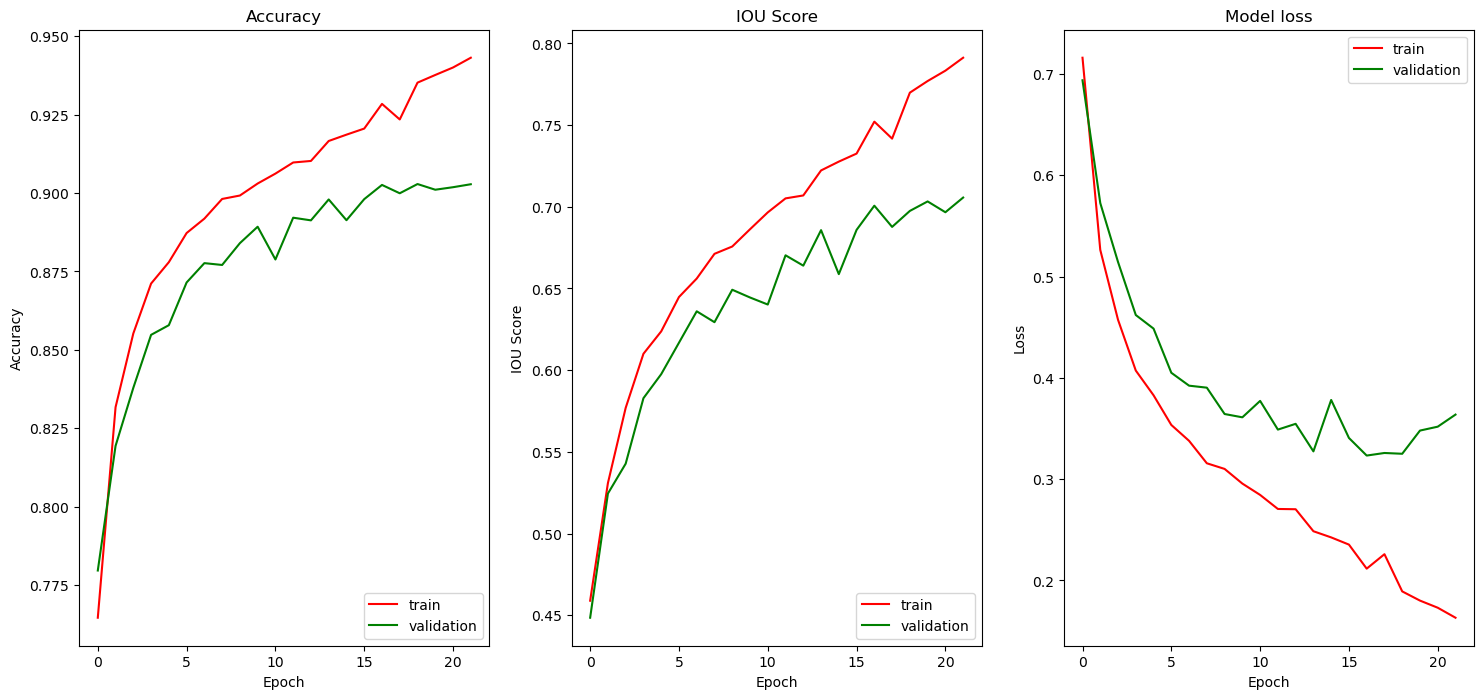

In [46]:
if mask_one_hot_encode:
    hist['accuracy'] = hist.pop('categorical_accuracy')
    hist['val_accuracy'] = hist.pop('val_categorical_accuracy')
else:
    hist['accuracy'] = hist.pop('sparse_categorical_accuracy')
    hist['val_accuracy'] = hist.pop('val_sparse_categorical_accuracy')
    
hist['iou'] = hist.pop('mean_IoU')
hist['val_iou'] = hist.pop('val_mean_IoU')

'''    
for k, v in hist.items():
    print(k, type(v))
''';

plot_performance(hist)

### Visualisation des prédictions et comparaison avec les images réelles et masques 8 categ

Data for batch #6 on 166 batches
Taille du batch d'image input : (3, 128, 128, 3)
Taille d'une image input : (128, 128, 3)
Taille du batch d'annotations: (3, 128, 128, 1)
Taille d'une image d'annotation : (128, 128, 1)
1/1 [==============================] - 5s 5s/step


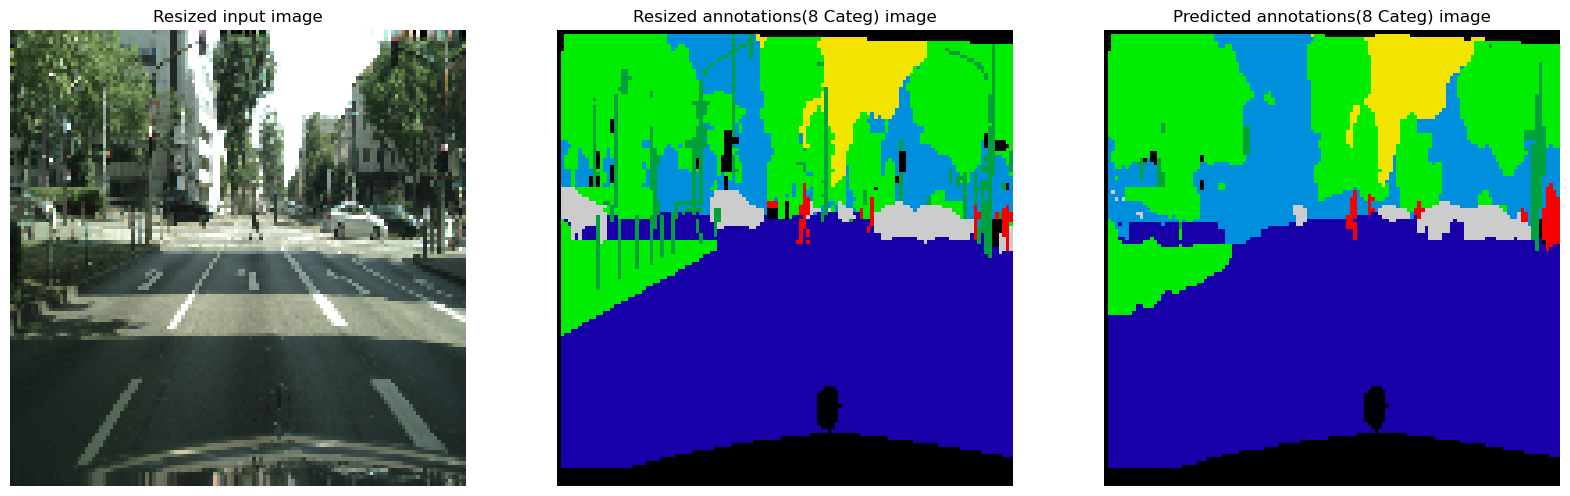

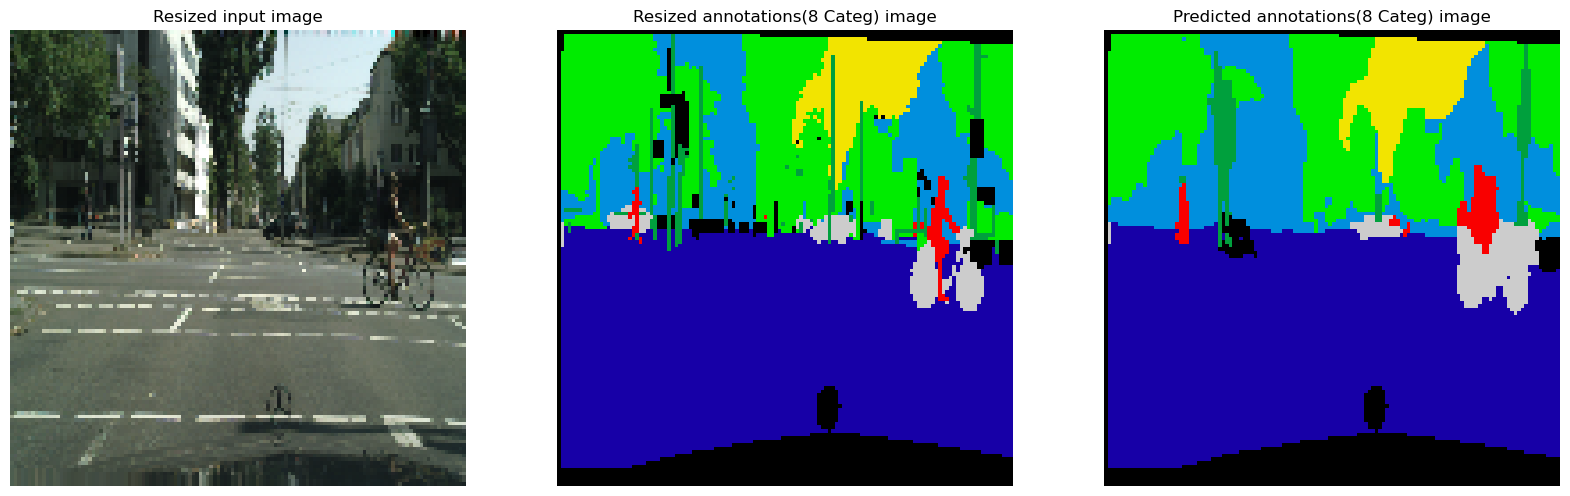

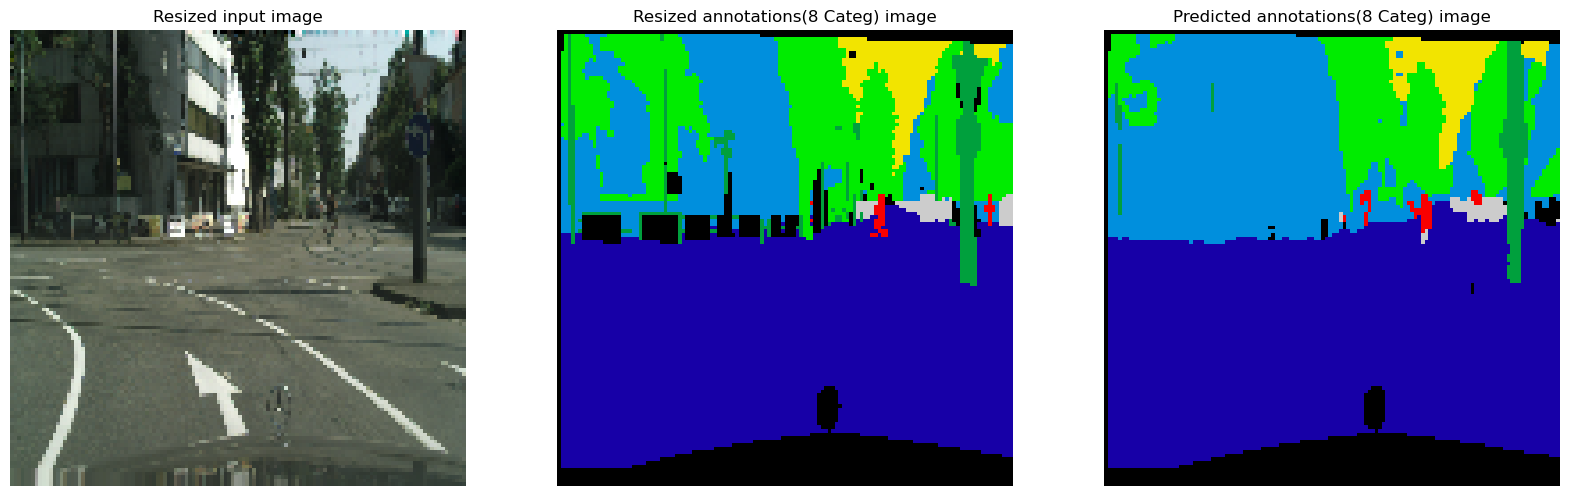

In [47]:
display_batch_predict(HRNetOCR, test_dataloader, 5,0,3)

### Sauvegarde des résultats d'évaluation,  training_time et nombre d'epochs

In [48]:
results['HRNetOCR']['training_time_minutes'] = training_time
results['HRNetOCR']['nb_epochs'] = nb_epochs

scores = HRNetOCR.evaluate(test_dataloader)
print(scores)

results['HRNetOCR']['loss'] = scores[0]
results['HRNetOCR']['categorical_accuracy'] = scores[1]
results['HRNetOCR']['mean_IoU'] = scores[2]

166/166 [==============================] - 36s 170ms/step - loss: 0.3908 - sparse_categorical_accuracy: 0.8933 - mean_IoU: 0.6302
[0.39083024859428406, 0.8932557702064514, 0.6302495002746582]


***
<a class="anchor" id="partie_2_3"></a><b><h2><font color=purple>2.3/ Comparaison</font></h2></b>

In [49]:
results_df = pd.DataFrame.from_dict(results, orient='index')
results_df

,training_time_minutes,categorical_accuracy,mean_IoU,loss,nb_epochs
unet2_mobilenet,30,0.849978,0.575731,0.537702,16
HRNetOCR,162,0.893256,0.630250,0.390830,22


### Graphe de comparaison

In [50]:
# Créons la méthode qui va dessiner l'ensemble des graphes
def drawMultipleBarPlot(dataFrame, xVar, allVarList, title, nbRow, nbCols, width=20, height=12, fontSize=20):

    # on crée la figure avec les graphes sur 3 lignes et 5 colonnes
    figure, axes = plt.subplots(nbRow, nbCols)
    figure.set_size_inches(width, height)

    for yVar, axe in zip(allVarList, axes.flat):
        # if xVar in ['Light Gradient Boosting Machine', 'Dummy Classifier']:
        sns.barplot(x=yVar,
                    y=xVar,
                    # showfliers=False,
                    orient='h',
                    ax=axe,
                    data=dataFrame)

    figure.suptitle(title, fontsize=fontSize)
    figure.tight_layout()

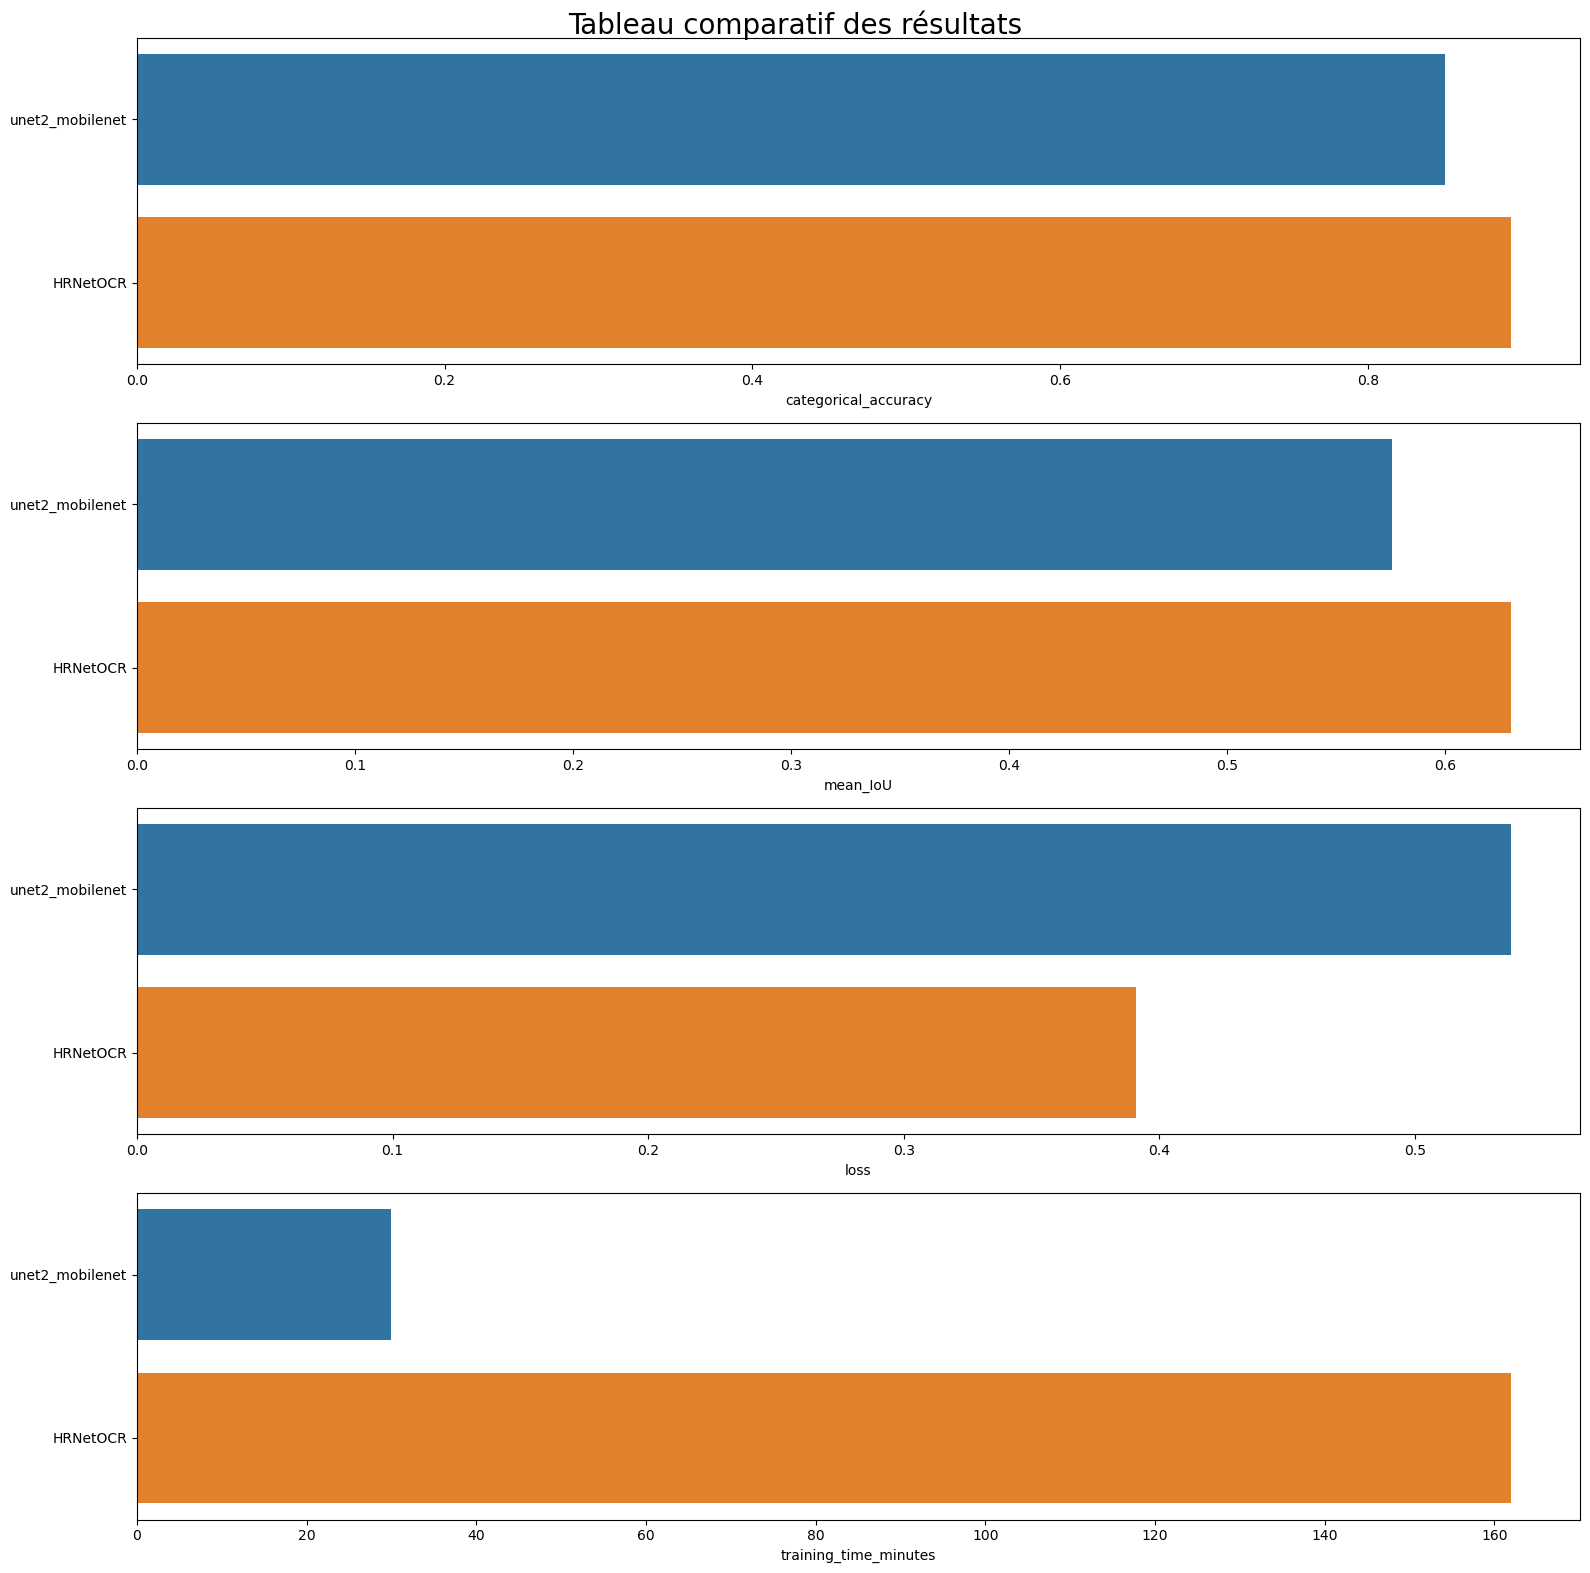

In [51]:
title = "Tableau comparatif des résultats"
metric_vars_dp = [
    'categorical_accuracy'
    ,'mean_IoU'
    ,'loss'
    ,'training_time_minutes'
    ,'nb_epochs'
]
mfs.drawMultipleBarPlot(results_df, results_df.index, metric_vars_dp, title, 4, 1, 16, 16, 20) 

### Ici nous pouvons voir que le nouveau modèle conduit à de meilleurs résultats de métriques que ce soit pour la Categorical Accuracy ou le meanIoU, son défaut étant le temps d'entrainement qui est bien plus long.

[](#sommaire)